MD# 06 · From PD to policy: profit, cutoff and impact

**Northvale Credit is a fictional lender; the data is public Lending Club loans.**

Question: where should Northvale draw the line, and what is it worth? Steps (in `src/northvale/pnl.py`): verify the cash fields, measure G (interest earned on loans that pay off) and L (loss on defaults) on the training window, choose cutoffs on the validation window by expected profit, and judge them once on the test window with the cash each loan returned. No time value of money.

In [1]:
import json
import warnings

import pandas as pd
from IPython.display import Image, display

from northvale import config as C

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 20)
m = json.loads(C.METRICS.read_text())


def fig(name, width=900):
    display(Image(filename=str(C.FIGURES / f"{name}.png"), width=width))

MD## 1. Cash checks

In [2]:
pd.Series(m["pnl"]["cash"])

identity_max_abs_residual       0.0100
identity_share_within_1_cent    1.0000
good_principal_repaid_share     1.0000
bad_principal_repaid_share      0.4203
bad_interest_share              0.1419
bad_recoveries_share            0.0754
bad_collection_fee_share        0.0121
bad_with_recovery_share         0.7780
funded_equals_requested_share   1.0000
dtype: float64

MD## 2. Assumptions calibrated on 2012-2014

In [3]:
pd.read_csv(C.TABLES / "pnl_assumptions_by_band.csv")

,rate_band,G_base,G_low,G_high,L_by_band,train_default_rate,n_train,breakeven_pd
0,<8%,0.0951,0.0934,0.0984,0.3725,0.0470,45202,0.0726
1,8-11%,0.1301,0.1285,0.1329,0.3535,0.0870,60726,0.1389
2,11-14%,0.1689,0.1677,0.1738,0.3568,0.1277,90114,0.2022
3,14-17%,0.2037,0.2018,0.2065,0.3554,0.1763,65380,0.2516
4,17-20%,0.2460,0.2393,0.2548,0.3641,0.2159,33602,0.3038
5,20%+,0.2906,0.2871,0.3061,0.3713,0.2535,11438,0.3516


In [4]:
a = m["pnl"]["assumptions"]
pd.Series({"L (net loss per $ defaulted)": a["L"], "principal-years per $": a["principal_years"],
           "cost of funds (annual, base)": a["cost_of_funds"]["base"], "opex (base)": a["opex"]["base"],
           "total cost per $ (base)": a["cost_rate_base"]})

L (net loss per $ defaulted)   0.3591
principal-years per $          1.3030
cost of funds (annual, base)   0.0400
opex (base)                    0.0100
total cost per $ (base)        0.0621
dtype: float64

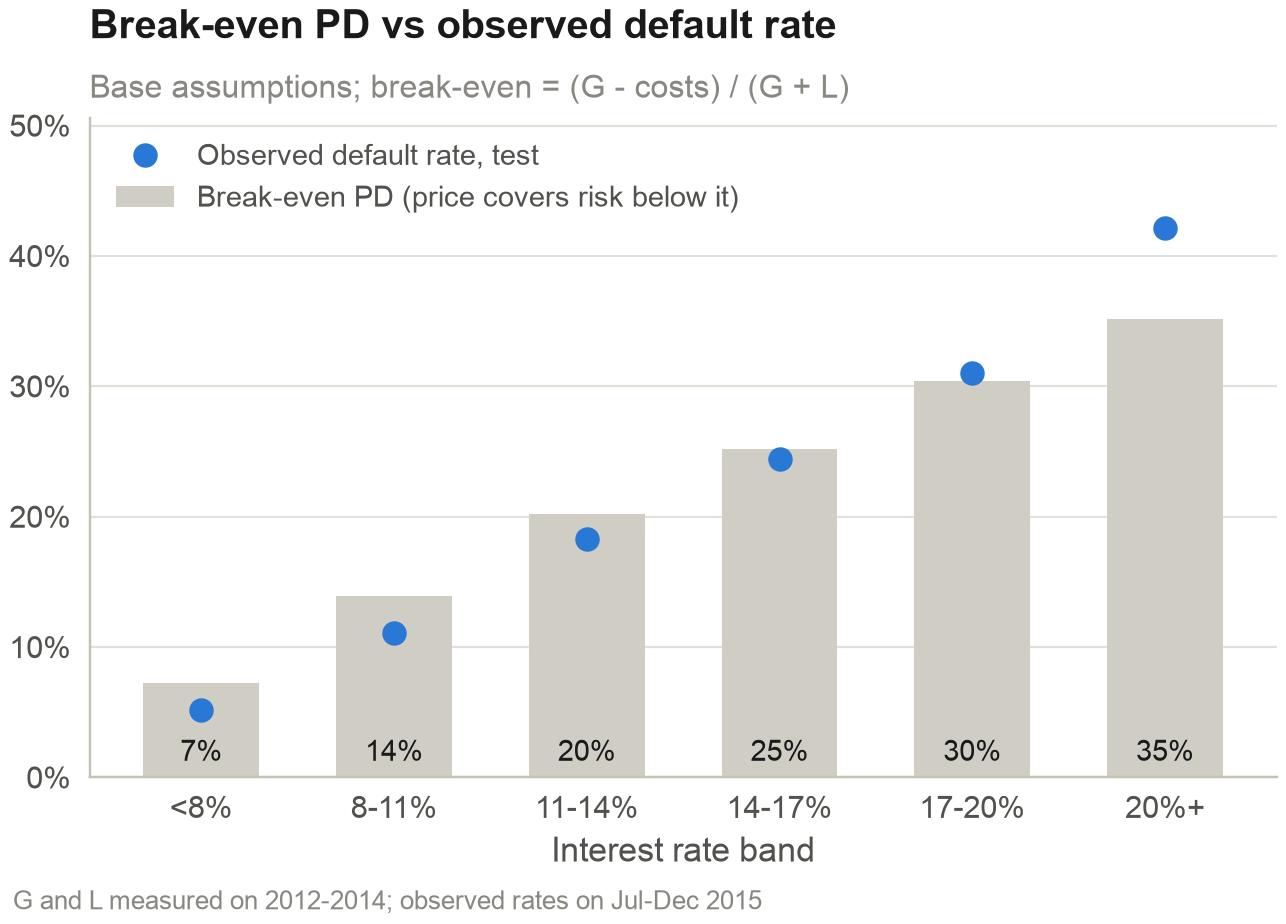

In [5]:
fig("breakeven_by_band", 600)

MD## 3. Policy curves on the test window

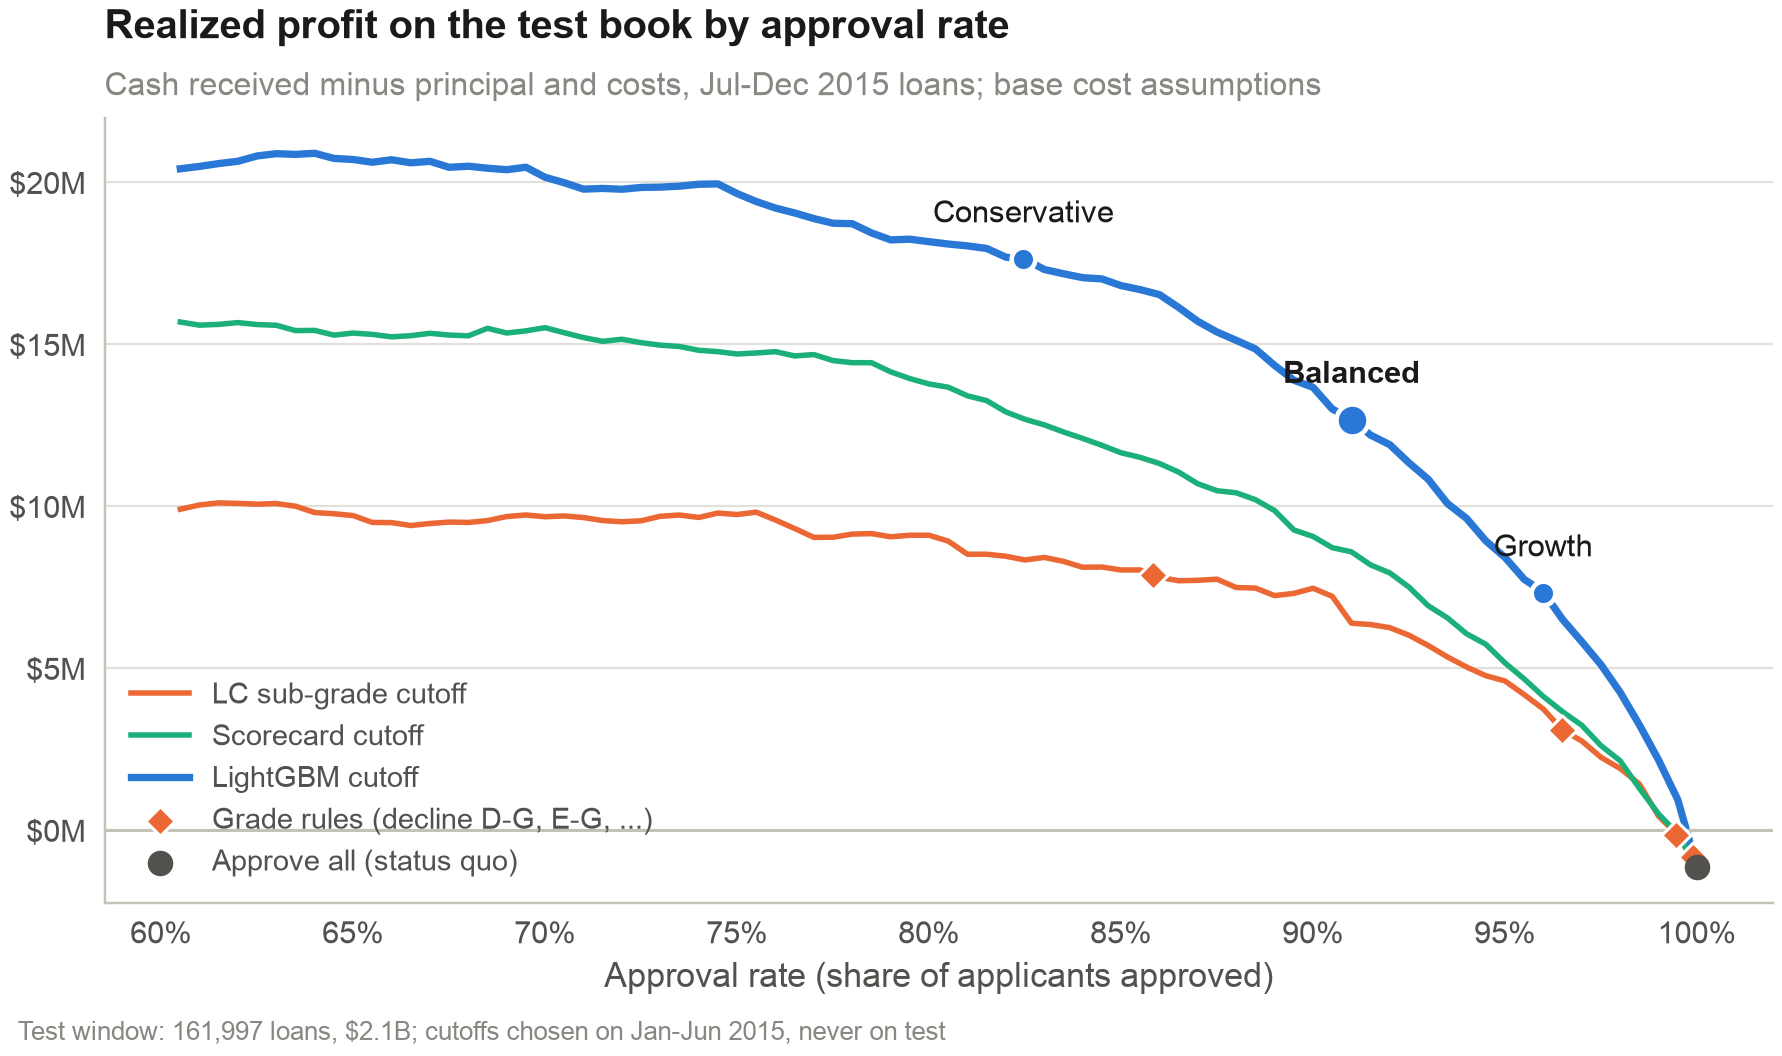

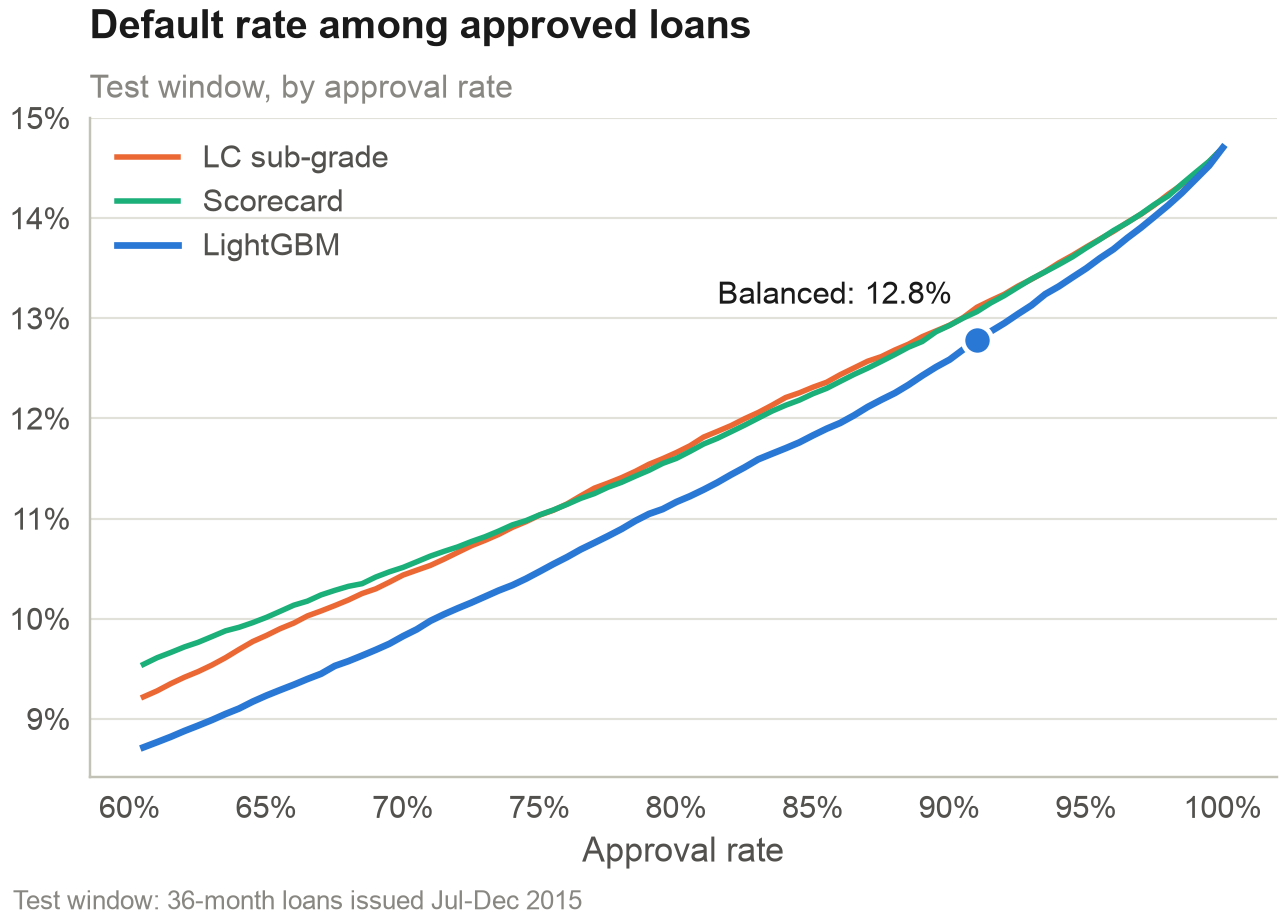

In [6]:
fig("policy_profit_curve")
fig("policy_default_curve", 600)

In [7]:
comp = pd.read_csv(C.TABLES / "policy_comparison_test.csv")
comp[["policy", "approval_rate", "volume_share", "default_rate", "net_credit_loss", "expected_profit", "realized_profit"]]

,policy,approval_rate,volume_share,default_rate,net_credit_loss,expected_profit,realized_profit
0,Approve all (status quo),1.0000,1.0000,0.1470,"116,938,625.3309","22,569,699.2352","-1,133,233.0418"
1,Decline G,0.9991,0.9993,0.1467,"116,537,716.8427","22,582,946.6188","-830,357.8329"
2,LightGBM at same approval as Decline G,0.9991,0.9988,0.1467,"116,299,089.3179","22,954,914.8677","-554,349.6045"
3,Decline F-G,0.9946,0.9958,0.1454,"115,168,538.4281","22,438,986.6674","-150,848.1618"
4,LightGBM at same approval as Decline F-G,0.9946,0.9941,0.1451,"114,229,597.9961","24,073,881.4296","997,130.5074"
5,Decline E-G,0.9650,0.9676,0.1396,"106,546,004.6098","21,426,244.6668","3,101,578.6211"
6,LightGBM at same approval as Decline E-G,0.9650,0.9649,0.1380,"104,638,725.8474","28,316,654.0397","6,519,761.1180"
7,Decline D-G,0.8583,0.8660,0.1241,"82,570,247.8587","16,957,386.4194","7,882,656.3189"
8,LightGBM at same approval as Decline D-G,0.8583,0.8669,0.1194,"80,131,322.8499","33,975,081.5010","16,576,591.0682"
9,LightGBM conservative,0.8246,0.8359,0.1151,"74,261,760.2253","34,586,144.9306","17,636,817.8832"


MD## 4. The three options (cutoffs chosen on January-June 2015)

In [8]:
keys = ["pd_cutoff", "valid_approval_rate", "approval_rate", "volume_share", "default_rate", "default_rate_change",
        "profit_change", "loss_avoided", "declined_n", "declined_default_rate", "good_profit_forgone"]
pd.DataFrame({k: {c: v[c] for c in keys} for k, v in m["pnl"]["options"].items()})

,conservative,balanced,growth
pd_cutoff,0.2272,0.2788,0.3332
valid_approval_rate,0.8100,0.9000,0.9550
approval_rate,0.8246,0.9100,0.9599
volume_share,0.8359,0.9139,0.9601
default_rate,0.1151,0.1278,0.1369
default_rate_change,-0.0320,-0.0192,-0.0101
profit_change,"18,770,050.9250","13,814,467.8281","8,459,291.2188"
loss_avoided,"42,676,865.1056","26,046,408.8318","13,794,781.2221"
declined_n,"28,417.0000","14,575.0000","6,494.0000"
declined_default_rate,0.2973,0.3417,0.3901


MD## 5. Expected vs realized, and drift in the loss per default

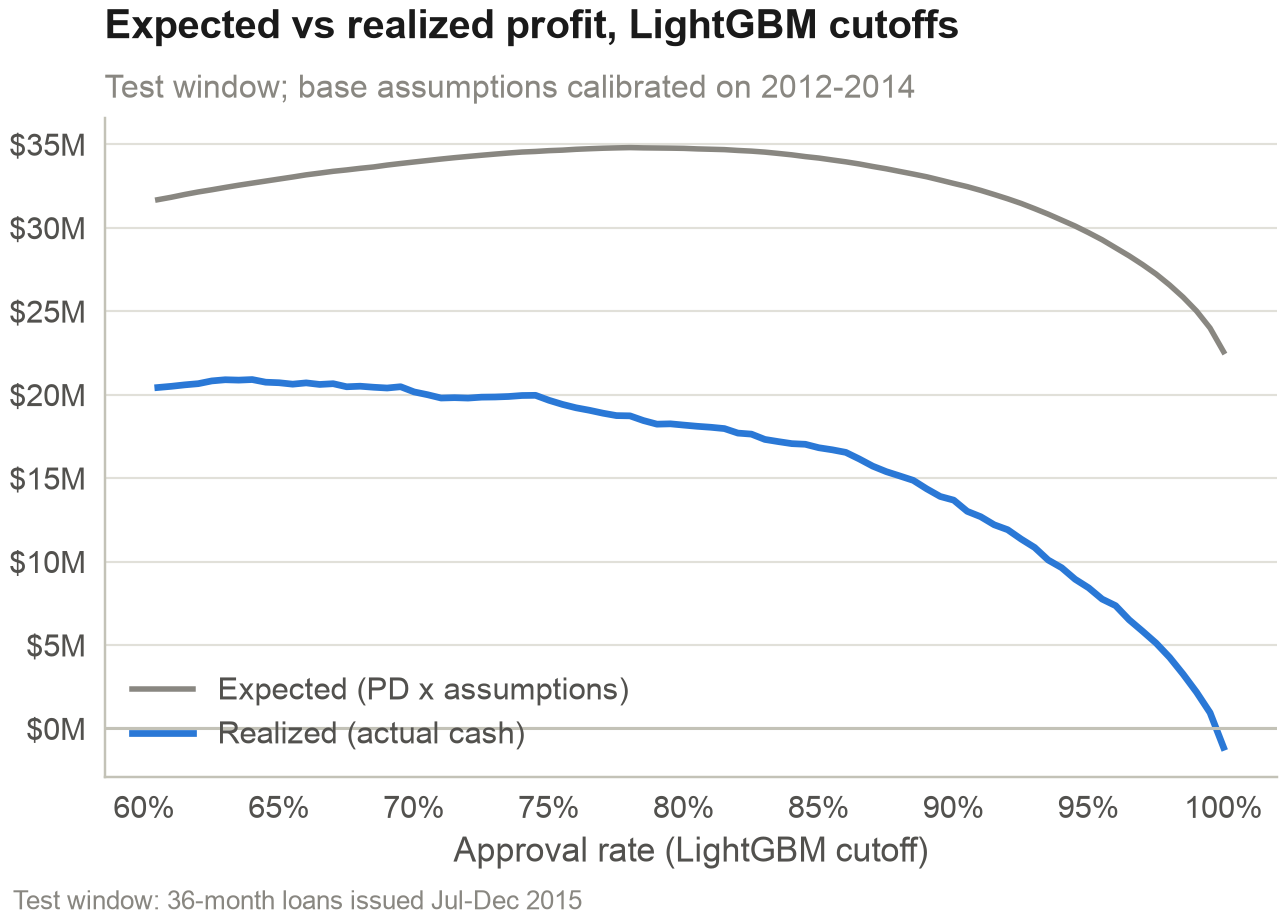

,training (assumption),validation 2015 H1,test 2015 H2
L,0.3591,0.3809,0.3943


In [9]:
fig("expected_vs_realized", 600)
pd.DataFrame({"training (assumption)": {"L": a["L"]}, "validation 2015 H1": {"L": m["pnl"]["drift"]["valid"]["L"]},
              "test 2015 H2": {"L": m["pnl"]["drift"]["test"]["L"]}})

MD## 6. Sensitivity and annual view

In [10]:
display(pd.read_csv(C.TABLES / "scenario_sensitivity.csv", index_col=0))
pd.Series({**m["pnl"]["annualisation"], **{f"annual_{k}": v for k, v in m["pnl"]["annual"].items()}})

,G_mid,L,cost_of_funds,opex,cost_rate,status_quo_expected_profit,policy_expected_profit,expected_profit_change,realized_profit_change,status_quo_realized_profit,annual_realized_profit_change,annual_expected_profit_change
low,0.1738,0.3515,0.0300,0.0050,0.0441,"69,150,797.0414","74,461,535.6390","5,310,738.5976","10,590,527.2586","36,299,783.0975","21,181,054.5171","10,621,477.1952"
base,0.1689,0.3591,0.0400,0.0100,0.0621,"22,569,699.2352","32,231,314.4164","9,661,615.1812","13,814,467.8281","-1,133,233.0418","27,628,935.6563","19,323,230.3624"
high,0.1677,0.3830,0.0600,0.0200,0.0982,"-62,463,067.1320","-44,547,412.6067","17,915,654.5253","20,262,348.9673","-75,999,265.3205","40,524,697.9346","35,831,309.0505"


months_in_test                              6.0000
factor                                      2.0000
annual_loans                          323,994.0000
annual_amount                   4,152,335,600.0000
annual_profit_change               27,628,935.6563
annual_loss_avoided                52,092,817.6636
annual_defaults_avoided                 9,960.0000
annual_volume_lost                357,622,350.0000
annual_expected_profit_change      19,323,230.3624
dtype: float64

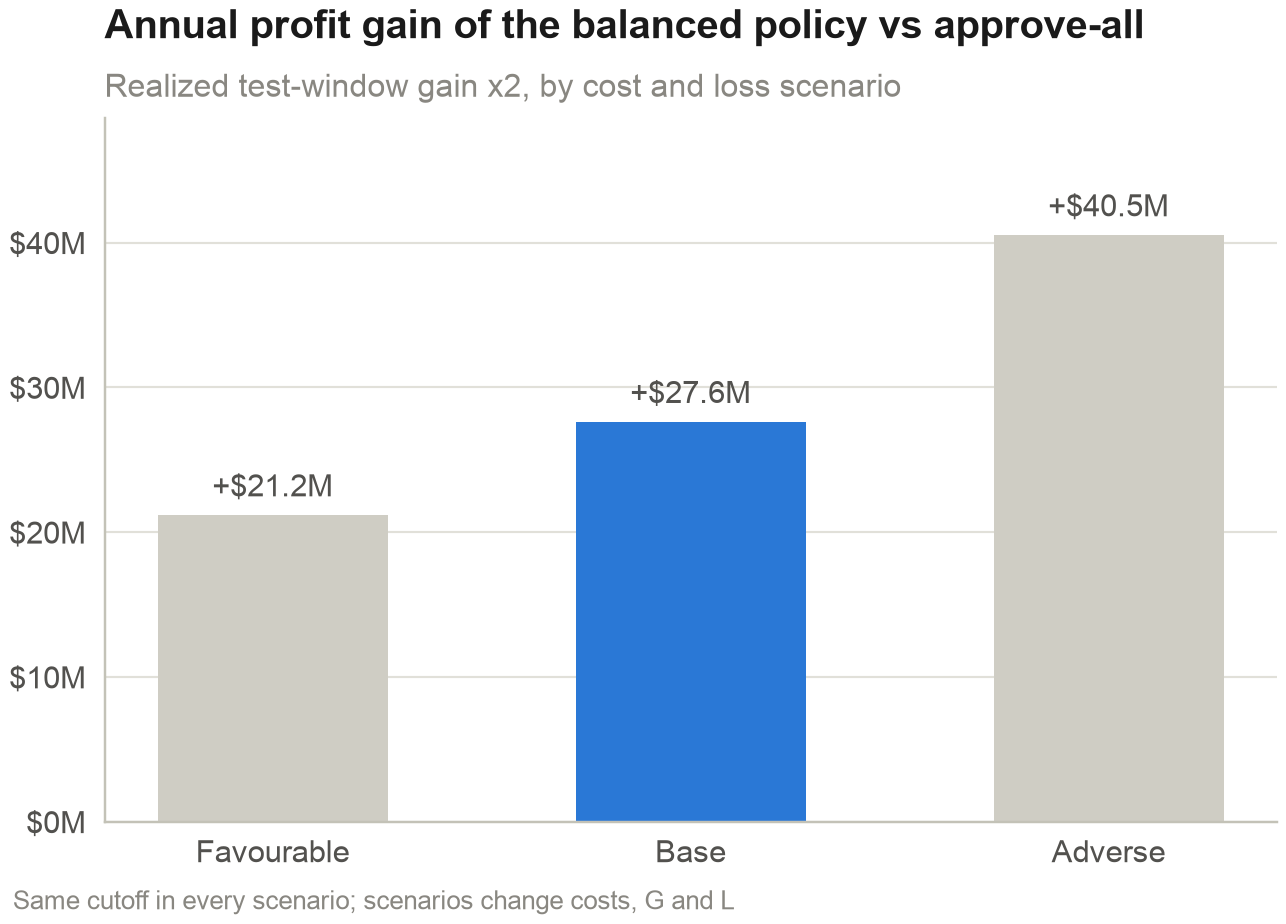

In [11]:
fig("scenario_impact", 600)

MD**Answer.** Recommend the balanced cutoff: it meets the committee's volume constraint, cuts the default rate and turns a break-even book into a profitable one on loans no model saw. The conservative option earns more on this test window but gives up far more volume (options table above), on a model trained only on approved loans. All projections hold only under the stated assumptions.